# Figures of the paper

*Network-Induced Strategic Communication in Opinion Dynamics* ([arXiv:2607.16036](https://arxiv.org/abs/2607.16036)).

Running all cells regenerates the three simulation figures of the paper and saves them in `paper/figures_paper_1/`, which is where `paper/main.tex` reads them from:

| Figure | File | Preset |
|---|---|---|
| Fig. 2 — exaggeration factor $\xi_i$ on example graphs | `fig_section3_xi_topology_gallery_compact.pdf` | — |
| Fig. 4 — Karate Club, three signaling maps | `fig_section7_karate_private_public_signature.pdf` | `presets/figure4_karate_club.json` |
| Fig. 5 — two-group network, persistent public switching | `fig_section7_private_public_signature.pdf` | `presets/figure5_two_group.json` |

Figs. 1 and 3 are TikZ drawings inside `main.tex`. Figs. 4 and 5 use LaTeX for their labels (`text.usetex`); without a LaTeX installation they fall back to Matplotlib's mathtext.

In [1]:
# Setup: imports, output folder, LaTeX check
from __future__ import annotations

import shutil
import sys
from pathlib import Path

import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


def find_repo_root() -> Path:
    """Locate the repository root (the folder containing strategic_coda/ and paper/)."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "strategic_coda").is_dir() and (candidate / "paper").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from inside the repository.")


ROOT_DIR = find_repo_root()
if str(ROOT_DIR) not in sys.path:  # works without `pip install -e .` too
    sys.path.insert(0, str(ROOT_DIR))

from strategic_coda import StrategicCODASimulator, compute_xi, load_preset  # noqa: E402

# Figures are written straight into the paper sources, where main.tex reads them.
OUTPUT_DIR = ROOT_DIR / "paper" / "figures_paper_1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Figs. 4 and 5 typeset their labels with LaTeX, as in the paper.
USE_TEX = shutil.which("latex") is not None
if not USE_TEX:
    print("LaTeX not found: Figs. 4-5 will use mathtext (labels look slightly different).")
print(f"Figures will be saved to {OUTPUT_DIR.relative_to(ROOT_DIR).as_posix()}/")


Figures will be saved to paper/figures_paper_1/


## Fig. 2 — Network-induced exaggeration factor

$N=12$, common inertia $\alpha_i=0.5$, uniform weights over neighbors (row-normalized). Nodes are colored by $\xi_i$ (Definition 2).

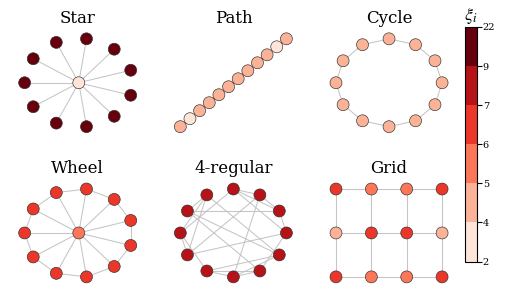

Compact topology gallery for graph-induced exaggeration
N=12, alpha=0.50, row-normalized undirected weights
Star     xi_min= 2.00  xi_max=22.00  xi_mean=20.33  xi=[ 2. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22.]
Path     xi_min= 2.40  xi_max= 4.00  xi_mean= 3.73  xi=[4.  2.4 4.  4.  4.  4.  4.  4.  4.  4.  2.4 4. ]
Cycle    xi_min= 4.00  xi_max= 4.00  xi_mean= 4.00  xi=[4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4. 4.]
Wheel    xi_min= 6.00  xi_max= 6.57  xi_mean= 6.53  xi=[6.   6.57 6.57 6.57 6.57 6.57 6.57 6.57 6.57 6.57 6.57 6.57]
4-regular xi_min= 8.00  xi_max= 8.00  xi_mean= 8.00  xi=[8. 8. 8. 8. 8. 8. 8. 8. 8. 8. 8. 8.]
Grid     xi_min= 4.44  xi_max= 6.32  xi_mean= 5.50  xi=[6.   5.11 5.11 6.   4.44 6.32 6.32 4.44 6.   5.11 5.11 6.  ]
Saved: paper/figures_paper_1/fig_section3_xi_topology_gallery_compact.pdf


In [2]:
# Fig. 2: network-induced exaggeration factor xi_i on example graphs
from dataclasses import dataclass

from matplotlib.colors import BoundaryNorm, ListedColormap

# Discrete xi classes (data-driven breakpoints, empty [3,4) bin removed
# after inspecting the true xi values: star hub=2, path min=2.4 share one class).
BOUNDS = np.array([2, 4, 5, 6, 7, 9, 22], dtype=float)
# Truncate Reds so the palest class is a visible pink, not near-white
# (keeps the lowest class legible and improves B/W-print separation).
_cmap_colors = plt.get_cmap("Reds")(np.linspace(0.10, 1.0, len(BOUNDS) - 1))
CMAP = ListedColormap(_cmap_colors)
NORM = BoundaryNorm(BOUNDS, CMAP.N)


@dataclass(frozen=True)
class TopologyPanel:
    label: str
    graph: nx.Graph
    pos: dict[int, np.ndarray]


def apply_compact_topology_style() -> None:
    """Use a compact, IEEE-friendly style close to the notebook cell-4 figures."""
    plt.rcParams.update(
        {
            "font.family": "serif",
            "axes.labelsize": 8,
            "font.size": 8,
            "legend.fontsize": 7,
            "xtick.labelsize": 7,
            "ytick.labelsize": 7,
            "axes.titlesize": 12,
            "axes.grid": False,
            "mathtext.fontset": "stix",
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )


def row_stochastic_weights_from_undirected(G: nx.Graph) -> np.ndarray:
    """Return W[i,j], the row-normalized weight receiver i assigns to source j."""
    n = G.number_of_nodes()
    W = np.zeros((n, n), dtype=float)
    for i in range(n):
        nbrs = sorted(G.neighbors(i))
        if not nbrs:
            raise ValueError(f"Node {i} has no neighbors.")
        W[i, nbrs] = 1.0 / len(nbrs)
    return W


def path_layout(n: int) -> dict[int, np.ndarray]:
    xs = np.linspace(-1.0, 1.0, n)
    theta = np.deg2rad(22.0)
    direction = np.array([np.cos(theta), np.sin(theta)])
    return {i: xs[i] * direction for i in range(n)}


def star_layout(n: int) -> dict[int, np.ndarray]:
    graph = nx.star_graph(n - 1)
    return nx.shell_layout(graph, nlist=[[0], list(range(1, n))])


def wheel_layout(n: int) -> dict[int, np.ndarray]:
    graph = nx.wheel_graph(n)
    return nx.shell_layout(graph, nlist=[[0], list(range(1, n))])


def grid_graph_with_layout(n: int) -> tuple[nx.Graph, dict[int, np.ndarray]]:
    rows = int(np.floor(np.sqrt(n)))
    while rows > 1 and n % rows != 0:
        rows -= 1
    cols = n // rows
    graph = nx.convert_node_labels_to_integers(nx.grid_2d_graph(rows, cols), ordering="sorted")

    pos: dict[int, np.ndarray] = {}
    for node in graph.nodes:
        row, col = divmod(node, cols)
        x = (col - 0.5 * (cols - 1)) / max(cols - 1, 1)
        y = (0.5 * (rows - 1) - row) / max(rows - 1, 1)
        pos[node] = np.array([x, y])
    return graph, pos


def build_topology_panels(n: int = 12) -> list[TopologyPanel]:
    """Canonical graph families with fixed N for a structural xi comparison."""
    wheel_graph = nx.wheel_graph(n)
    regular_graph = nx.random_regular_graph(4, n, seed=42)
    grid_graph, grid_pos = grid_graph_with_layout(n)
    return [
        TopologyPanel("Star", nx.star_graph(n - 1), star_layout(n)),
        TopologyPanel("Path", nx.path_graph(n), path_layout(n)),
        TopologyPanel("Cycle", nx.cycle_graph(n), nx.shell_layout(nx.cycle_graph(n))),
        TopologyPanel("Wheel", wheel_graph, wheel_layout(n)),
        TopologyPanel("4-regular", regular_graph, nx.circular_layout(regular_graph)),
        TopologyPanel("Grid", grid_graph, grid_pos),
    ]


def draw_topology_panel(
    ax: plt.Axes,
    panel: TopologyPanel,
    xi: np.ndarray,
    cmap,
    norm,
) -> None:
    """Draw one compact graph panel colored by the graph-induced xi profile."""
    nx.draw_networkx_edges(
        panel.graph,
        panel.pos,
        ax=ax,
        edge_color="0.76",
        width=0.75,
        alpha=0.95,
    )
    nx.draw_networkx_nodes(
        panel.graph,
        panel.pos,
        ax=ax,
        node_color=cmap(norm(xi)),
        node_size=74,
        linewidths=0.45,
        edgecolors="0.18",
    )
    ax.set_title(panel.label, pad=1.8)
    ax.set_axis_off()
    ax.margins(0.08)


def save_compact_xi_topology_gallery(
    n: int = 12,
    alpha: float = 0.5,
) -> tuple[Path, list[dict[str, object]]]:
    """Generate and save the compact topology-to-xi gallery."""

    panels = build_topology_panels(n)
    alpha_vec = np.full(n, alpha, dtype=float)
    records: list[dict[str, object]] = []
    for panel in panels:
        W = row_stochastic_weights_from_undirected(panel.graph)
        xi, _ = compute_xi(W, alpha_vec, ensure_valid_graph=True)
        records.append({"panel": panel, "W": W, "xi": xi})

    fig, axes = plt.subplots(2, 3, figsize=(5.35, 3.05))
    for ax, record in zip(axes.ravel(), records):
        draw_topology_panel(
            ax,
            record["panel"],
            np.asarray(record["xi"], dtype=float),
            CMAP,
            NORM,
        )

    sm = plt.cm.ScalarMappable(cmap=CMAP, norm=NORM)
    sm.set_array([])

    # boundaries/values passed explicitly so spacing="uniform" actually
    # gives every class equal height (colorbar can't infer this from the
    # mappable alone with a BoundaryNorm).
    cbar = fig.colorbar(
        sm,
        ax=axes.ravel().tolist(),
        fraction=0.045,
        pad=0.06,
        boundaries=BOUNDS,
        values=0.5 * (BOUNDS[:-1] + BOUNDS[1:]),
        spacing="uniform",
        ticks=BOUNDS,
    )
    cbar.set_ticklabels([f"{b:g}" for b in BOUNDS])
    cbar.ax.set_ylabel(r"$\xi_i$", rotation=0, fontsize=13, labelpad=8)
    cbar.ax.yaxis.set_label_coords(0.5, 1.09)
    cbar.ax.tick_params(labelsize=7, pad=1)

    fig.subplots_adjust(left=0.015, right=0.85, bottom=0.02, top=0.88, wspace=0.15, hspace=0.34)
    out_path = OUTPUT_DIR / "fig_section3_xi_topology_gallery_compact.pdf"
    fig.savefig(out_path, dpi=300, format="pdf")
    plt.show()
    plt.close(fig)

    return out_path, records


apply_compact_topology_style()
out_path, topology_records = save_compact_xi_topology_gallery(n=12, alpha=0.5)

print("Compact topology gallery for graph-induced exaggeration")
print("======================================================")
print("N=12, alpha=0.50, row-normalized undirected weights")
for record in topology_records:
    panel = record["panel"]
    xi = np.asarray(record["xi"], dtype=float)
    print(
        f"{panel.label:8s} "
        f"xi_min={np.min(xi):5.2f}  "
        f"xi_max={np.max(xi):5.2f}  "
        f"xi_mean={np.mean(xi):5.2f}  "
        f"xi={np.round(xi, 2)}"
    )
print(f"Saved: {out_path.relative_to(ROOT_DIR).as_posix()}")

## Fig. 4 — Consensus versus clustering on the Karate Club network

$\alpha_i=0.5$, $x_i(0)\sim\mathcal U[-1,1]$, $T=30$, $L=5$. The influence weights $w_{ij}$ are proportional to the interaction counts of Zachary's data set (`weight_mode="karate_weights"`).

In [3]:
# Fig. 4 (simulation): Karate Club network under the three signaling maps.
# All parameters come from presets/figure4_karate_club.json; only
# signal_function changes between the three runs.

KARATE_SIGNATURE_PRESET = load_preset("figure4_karate_club")
KARATE_SIGNATURE_ALPHA = KARATE_SIGNATURE_PRESET.alpha
KARATE_SIGNATURE_L = KARATE_SIGNATURE_PRESET.L
KARATE_SIGNATURE_T = KARATE_SIGNATURE_PRESET.steps
KARATE_SIGNATURE_OPINION_SEED = KARATE_SIGNATURE_PRESET.opinion_seed
OUTPUT_DIR_KARATE_SIGNATURE = OUTPUT_DIR
KARATE_SIGNATURE_COLORS = {
    "Mr. Hi": "#d55e00",
    "Officer": "#0072b2",
}

KARATE_SIGNATURE_LINESTYLES = {
    "Mr. Hi": "-",
    "Officer": "--",
}


def karate_agent_linestyles(sim: StrategicCODASimulator) -> list[str]:
    """Linestyle per agent, matching the faction color mapping."""
    return [KARATE_SIGNATURE_LINESTYLES.get(club, "-") for club in karate_node_clubs(sim)]

# (name, signal_function, panel title)
KARATE_SIGNATURE_REGIMES = [
    ("linear", "linear", r"$s_i(x)=x$"),
    ("saturated", "saturated", r"$s_i(x)=\mathrm{sat}(\xi_i x)$"),
    ("quantized", "quantized", r"$s_i(x)=q_i(x)$"),
]


def make_karate_signature_config(signal_function: str):
    """Shared Karate Club configuration; only signal_function changes."""
    return KARATE_SIGNATURE_PRESET.replace(signal_function=signal_function)


def karate_node_clubs(sim: StrategicCODASimulator) -> list[str]:
    """Return the empirical Karate Club faction for each node."""
    clubs = nx.get_node_attributes(sim.base_graph, "club")
    return [clubs.get(i, "Mr. Hi") for i in range(sim.N)]


def karate_agent_colors(sim: StrategicCODASimulator) -> list[str]:
    """Color agents by the two Karate Club factions."""
    return [KARATE_SIGNATURE_COLORS.get(club, "#444444") for club in karate_node_clubs(sim)]


def karate_tail_switch_count(signals: np.ndarray, window: int = 30) -> int:
    """Count tail time steps where at least one public signal changes."""
    tail = np.round(signals[-window:], 8)
    return int(np.sum(np.any(np.abs(np.diff(tail, axis=0)) > 1e-8, axis=1)))


def run_karate_signature_simulation() -> dict[str, object]:
    """Run the three communication regimes on the same Karate Club setup."""
    results: dict[str, object] = {}
    reference_sim: StrategicCODASimulator | None = None

    for name, signal_function, title in KARATE_SIGNATURE_REGIMES:
        cfg = make_karate_signature_config(signal_function)
        sim = StrategicCODASimulator(cfg)
        history, _ = sim.run(cfg.steps)
        signals = np.asarray([sim.get_public_signals(row) for row in history])
        if reference_sim is None:
            reference_sim = sim
        results[name] = {
            "sim": sim,
            "history": history,
            "signals": signals,
            "title": title,
            "signal_function": signal_function,
        }

    if reference_sim is None:
        raise RuntimeError("No Karate Club simulations were run.")
    results["reference_sim"] = reference_sim
    results["colors"] = karate_agent_colors(reference_sim)
    results["linestyles"] = karate_agent_linestyles(reference_sim)
    results["clubs"] = karate_node_clubs(reference_sim)

    results["x0"] = reference_sim._initial_opinions.copy()
    return results


# Run the simulation
karate_signature_results = run_karate_signature_simulation()

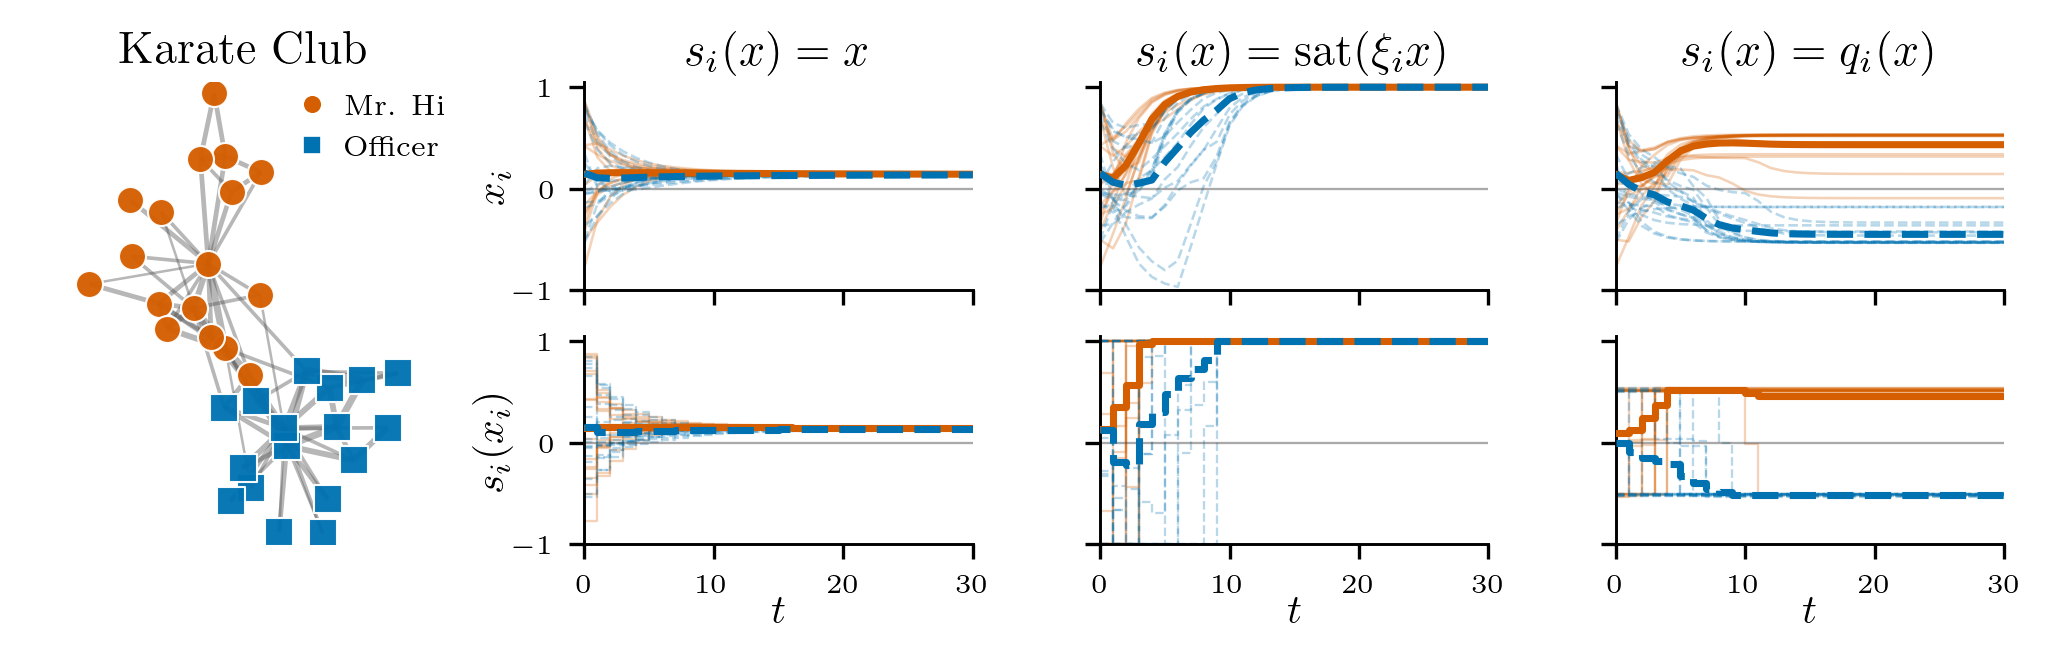

Karate Club private/public signature figure
alpha=0.50, L=5, T=30, opinion_seed=78
xi range=[4.005, 55.984]
linear     x(T)=[ 0.134, 0.144]  s(T)=[ 0.134, 0.144]  tail_span=0.484  public_switches=29
saturated  x(T)=[ 1.000, 1.000]  s(T)=[ 1.000, 1.000]  tail_span=1.967  public_switches=8
quantized  x(T)=[-0.534, 0.535]  s(T)=[-0.536, 0.535]  tail_span=1.054  public_switches=10
Saved: paper/figures_paper_1/fig_section7_karate_private_public_signature.pdf


In [4]:
# Fig. 4 (plot): private opinions x_i(t) (top) and public signals s_i(x_i(t)) (bottom)


def apply_karate_signature_style() -> None:
    """Use compact plotting defaults for the Karate private/public figure."""
    plt.rcParams.update(
        {   "font.family": "serif",
            "font.size": 8,
            "axes.labelsize": 10,
            "axes.titlesize": 8,
            "xtick.labelsize": 6.5,
            "ytick.labelsize": 6.5,
            "axes.linewidth": 0.7,
            "axes.grid": False,
            "grid.alpha": 0.14,
            "grid.linewidth": 0.45,
            "mathtext.fontset": "stix",
            "text.usetex": USE_TEX,
            "text.latex.preamble": r"\usepackage{amsmath} \usepackage{amssymb}",
            "pdf.fonttype":42,
            "ps.fonttype":42,
        }
    )


def draw_karate_signature_graph(ax: plt.Axes, sim: StrategicCODASimulator, colors: list[str]) -> None:
    """Draw the Karate Club network inside the left panel, filling it tightly."""
    G = sim.base_graph
    pos = sim.layout_pos

    # Calculate coordinates and center the graph
    pos_arr = np.array(list(pos.values()))
    xmin, ymin = pos_arr.min(axis=0)
    xmax, ymax = pos_arr.max(axis=0)
    cx, cy = (xmin + xmax) / 2.0, (ymin + ymax) / 2.0
    dx = max(xmax - xmin, 1e-9)
    dy = max(ymax - ymin, 1e-9)

    # Match the fill region's aspect ratio to the actual (tall, narrow) axes box
    fig = ax.figure
    bbox = ax.get_position()
    fig_w, fig_h = fig.get_size_inches()
    box_aspect = (bbox.width * fig_w) / (bbox.height * fig_h)  # width / height

    span_y = max(dy, dx / box_aspect)
    span_x = span_y * box_aspect

    padding = 0.05
    ax.set_xlim(cx - span_x / 2 * (1 + padding), cx + span_x / 2 * (1 + padding))
    ax.set_ylim(cy - span_y / 2 * (1 + padding), cy + span_y / 2 * (1 + padding))
    ax.set_aspect("equal", adjustable="box")

    weights = np.asarray([G[u][v].get("weight", 1.0) for u, v in G.edges()], dtype=float)
    if weights.size == 0:
        widths = 0.7
    else:
        widths = 0.35 + 1.85 * weights / weights.max()

    nx.draw_networkx_edges(
        G,
        pos,
        ax=ax,
        width=widths,
        edge_color="#555555",
        alpha=0.42,
    )

    clubs = karate_node_clubs(sim)  # already computed elsewhere
    shape_map = {"Mr. Hi": "o", "Officer": "s"}
    for club, shape in shape_map.items():
        nodelist = [i for i, c in enumerate(clubs) if c == club]

        nx.draw_networkx_nodes(
            G, pos, ax=ax,
            nodelist=nodelist,
            node_color=KARATE_SIGNATURE_COLORS[club],
            node_shape=shape,
            node_size=42,
            edgecolors="white", linewidths=0.5, alpha=0.96,
    )

    ax.set_axis_off()

    # Small inline legend for the two empirical factions
    legend_handles = [
        plt.Line2D(
            [0], [0],
            marker=shape_map[club], linestyle="none",
            markerfacecolor=color, markeredgecolor="white",
            markeredgewidth=0.4, markersize=4.5,
        )
        for club, color in KARATE_SIGNATURE_COLORS.items()
    ]

    legend = ax.legend(
        legend_handles,
        list(KARATE_SIGNATURE_COLORS.keys()),
        loc="upper right",
        ncol=1,
        frameon=False,
        fontsize=7,
        handletextpad=0.1,
        columnspacing=0.8,
        borderaxespad=0.0,
    )

    legend.set_clip_on(False)


def draw_karate_signature_time_panel(
    ax: plt.Axes,
    series: np.ndarray,
    colors: list[str],
    linestyles: list[str],
    ylabel: str,
    show_xlabel: bool,
    clubs: list[str] | None = None,
    stepped: bool = False,
    note: str | None = None,
) -> None:
    """Draw one compact Karate Club private/public panel."""
    time = np.arange(series.shape[0])
    for agent in range(series.shape[1]):
        if stepped:
            ax.step(time, series[:, agent], where="post", color=colors[agent],
                    linestyle=linestyles[agent], lw=0.55, alpha=0.28)
        else:
            ax.plot(time, series[:, agent], color=colors[agent],
                    linestyle=linestyles[agent], lw=0.62, alpha=0.28)

    if clubs is not None:
        for club, color in KARATE_SIGNATURE_COLORS.items():
            idx = [i for i, c in enumerate(clubs) if c == club]
            mean = series[:, idx].mean(axis=1)
            ls = KARATE_SIGNATURE_LINESTYLES.get(club, "-")
            if stepped:
                ax.step(time, mean, where="post", color=color, linestyle=ls,
                        lw=1.7, alpha=1.0, zorder=5)
            else:
                ax.plot(time, mean, color=color, linestyle=ls,
                        lw=1.7, alpha=1.0, zorder=5)

    ax.axhline(0.0, color="0.25", lw=0.55, alpha=0.45)
    ax.set_xlim(0, time[-1])
    ax.set_ylim(-1.0, 1.05)
    ax.set_yticks([-1, 0, 1])
    ax.set_ylabel(ylabel, labelpad=0)
    if show_xlabel:
        ax.set_xlabel(r"$t$", labelpad=-1)
    else:
        ax.set_xticklabels([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if note:
        ax.text(
            0.04,
            0.9,
            note,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=6.5,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 0.8},
        )


def save_karate_signature_figure(results: dict[str, object]) -> Path:
    """Save the full-width Karate Club private/public signature figure."""
    OUTPUT_DIR_KARATE_SIGNATURE.mkdir(parents=True, exist_ok=True)
    apply_karate_signature_style()

    fig = plt.figure(figsize=(7.0, 2.2), dpi=300)
    grid = fig.add_gridspec(
        2,
        4,
        width_ratios=[1.1, 1.0, 1.0, 1.0],  # Gave column 0 slightly more room
        height_ratios=[1.0, 1.0],
        left=0.035,
        right=0.975,
        bottom=0.18,
        top=0.88,
        wspace=0.32,                        # Marginally reduced to keep visual density tight
        hspace=0.22,
    )

    # 1. Align Title: Create a dummy top-left axes sharing the top row to host the aligned title
    title_ax = fig.add_subplot(grid[0, 0])
    title_ax.set_title("Karate Club", pad=4.5, fontsize=11)
    title_ax.set_axis_off()

    # 2. Draw Network: Create the actual graph axes spanning both rows
    graph_ax = fig.add_subplot(grid[:, 0])
    draw_karate_signature_graph(graph_ax, results["reference_sim"], results["colors"])

    # 3. Draw Subplots
    for col, (name, _signal_function, _title) in enumerate(KARATE_SIGNATURE_REGIMES, start=1):
        top_ax = fig.add_subplot(grid[0, col])
        bottom_ax = fig.add_subplot(grid[1, col])
        regime = results[name]

        draw_karate_signature_time_panel(
            top_ax,
            regime["history"],
            results["colors"],
            results["linestyles"],
            clubs=results["clubs"],
            ylabel=r"$x_i$",
            show_xlabel=False,
            note=None,
        )
        draw_karate_signature_time_panel(
            bottom_ax,
            regime["signals"],
            results["colors"],
            results["linestyles"],
            clubs=results["clubs"],
            ylabel=r"$s_i(x_i)$",
            show_xlabel=True,
            stepped=True,
            note=None,
        )
        top_ax.set_title(regime["title"], pad=4.5, fontsize=11)
        if col > 1:
            top_ax.set_yticklabels([])
            bottom_ax.set_yticklabels([])
            top_ax.set_ylabel("")
            bottom_ax.set_ylabel("")

    pdf_path = OUTPUT_DIR_KARATE_SIGNATURE / "fig_section7_karate_private_public_signature.pdf"
    fig.savefig(pdf_path, dpi=300, format="pdf", bbox_inches="tight", pad_inches=0.015)
    if "ipykernel" in sys.modules:
        plt.show()
    else:
        plt.close(fig)
    return pdf_path


# Plot the results
karate_signature_pdf = save_karate_signature_figure(karate_signature_results)

# Output simulation summary
print("Karate Club private/public signature figure")
print("===========================================")
print(
    f"alpha={KARATE_SIGNATURE_ALPHA:.2f}, L={KARATE_SIGNATURE_L}, "
    f"T={KARATE_SIGNATURE_T}, opinion_seed={KARATE_SIGNATURE_OPINION_SEED}"
)
ref_sim = karate_signature_results["reference_sim"]
print(f"xi range=[{ref_sim.xi.min():.3f}, {ref_sim.xi.max():.3f}]")
for name, _signal_function, _title in KARATE_SIGNATURE_REGIMES:
    regime = karate_signature_results[name]
    final_private = regime["history"][-1]
    final_public = regime["signals"][-1]
    tail_span = np.max(np.ptp(regime["history"][-30:], axis=0))
    public_switches = karate_tail_switch_count(regime["signals"])
    print(
        f"{name:10s} "
        f"x(T)=[{final_private.min(): .3f},{final_private.max(): .3f}]  "
        f"s(T)=[{final_public.min(): .3f},{final_public.max(): .3f}]  "
        f"tail_span={tail_span:.3f}  public_switches={public_switches}"
    )
print(f"Saved: {karate_signature_pdf.relative_to(ROOT_DIR).as_posix()}")

## Fig. 5 — Persistent public switching on a two-group network

Groups $\{1,2\}$ and $\{3,4,5\}$; same-group sources share weight $0.80$, cross-group sources share $\rho=0.20$ (`weight_mode="group_weights"`). $\alpha_i=0.05$, $L=5$, $T=20$, $\mathbf{x}(0)=(0.585,-0.459,-0.911,0.730,-0.487)$.

In [5]:
# Fig. 5 (simulation): five-node two-group network under the three signaling maps.
# All parameters come from presets/figure5_two_group.json; only
# signal_function changes between the three runs.

SECTION7_FIG_PRESET = load_preset("figure5_two_group")
SECTION7_FIG_X0 = np.array(
    [float(v) for v in SECTION7_FIG_PRESET.initial_opinions_manual.split(",")])
SECTION7_FIG_RHO = SECTION7_FIG_PRESET.cross_group_weight
SECTION7_FIG_ALPHA = SECTION7_FIG_PRESET.alpha
SECTION7_FIG_L = SECTION7_FIG_PRESET.L
SECTION7_FIG_T = SECTION7_FIG_PRESET.steps
SECTION7_FIG_TAIL_START = 0
OUTPUT_DIR_SECTION7_FIG = OUTPUT_DIR

SECTION7_FIG_COLORS = ["#b2182b", "#ef8a62", "#08306b", "#2171b5", "#6baed6"]

# (name, signal_function, panel title, note)
SECTION7_FIG_REGIMES = [
    ("linear", "linear", r"$s_i(x)=x$", ""),
    ("saturated", "saturated", r"$s_i(x)=\operatorname{sat}(\xi_i x)$", ""),
    ("quantized", "quantized", r"$s_i(x)=q_i(x)$", ""),
]


def run_section7_figure_simulation() -> dict[str, object]:
    """Simulate the three signaling regimes of Fig. 5."""
    results: dict[str, object] = {}
    for name, signal_function, title, note in SECTION7_FIG_REGIMES:
        sim = StrategicCODASimulator(
            SECTION7_FIG_PRESET.replace(signal_function=signal_function))
        history, _ = sim.run(SECTION7_FIG_T)
        results[name] = {
            "history": history,
            "signals": np.asarray([sim.get_public_signals(row) for row in history]),
            "title": title,
            "note": note,
            "signal_function": signal_function,
        }
    # Network quantities are identical across the three runs.
    results.update({
        "W": sim.W,
        "alpha_vec": sim.alpha_vec,
        "xi": sim.xi,
        "thresholds": sim.thresholds_matrix,
        "reconstruction_levels": sim.reconstruction_levels_matrix,
    })
    if not np.allclose(sim.history[0], SECTION7_FIG_X0):
        raise ValueError("Preset initial condition does not match x(0) of the paper.")
    return results


# Execute calculations
section7_results = run_section7_figure_simulation()


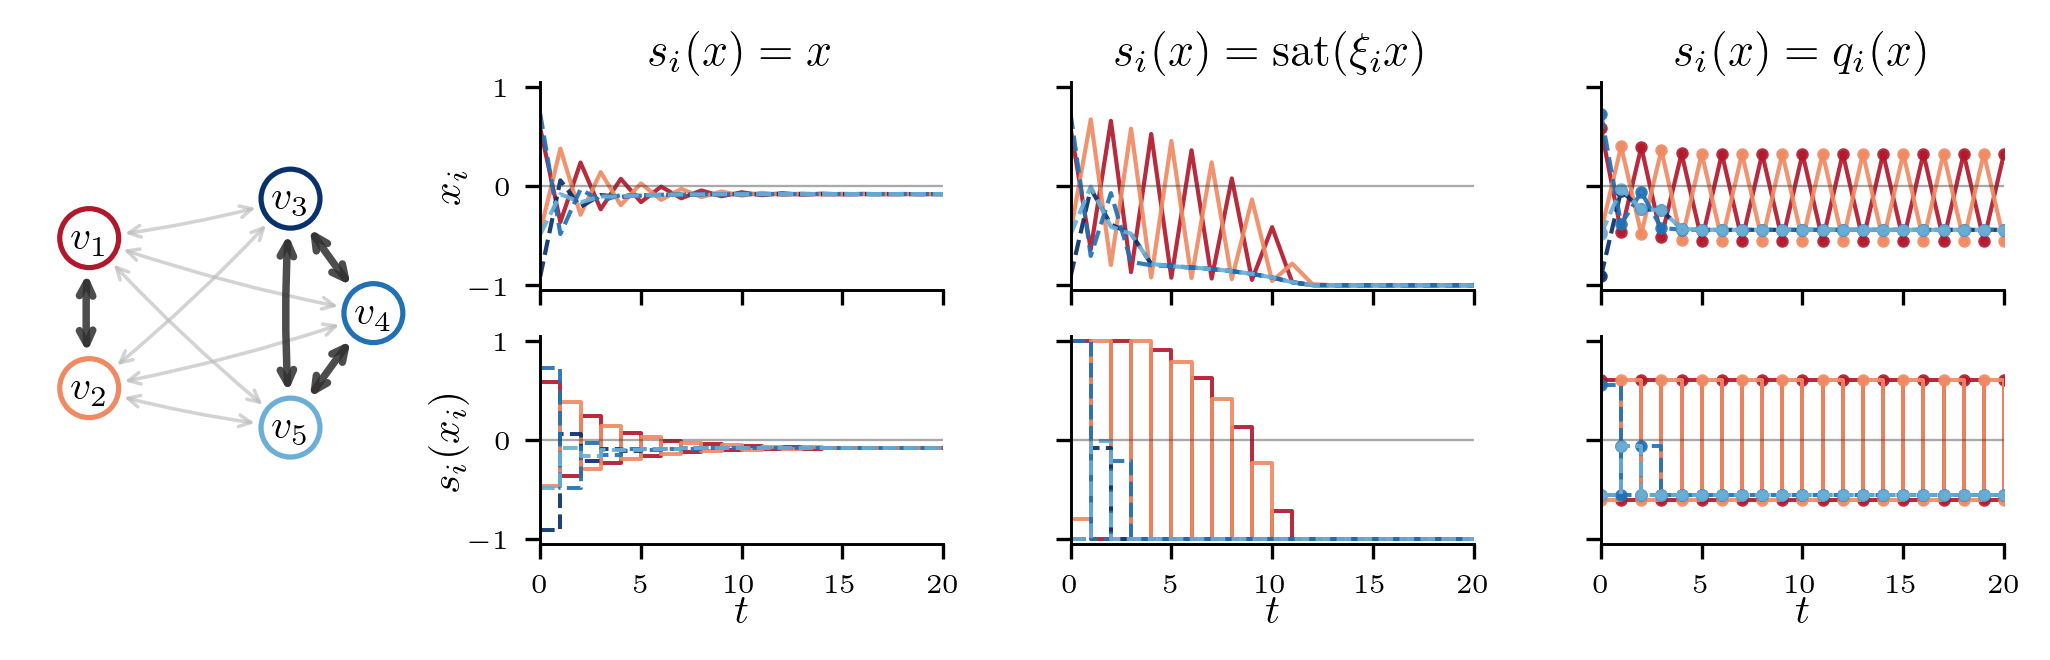

Section VII chattering figure
rho=0.20, alpha=0.05, L=5, T=20
x0= [ 0.585 -0.459 -0.911  0.73  -0.487]
xi= [1.728 1.728 2.987 2.987 2.987]
linear     x(T)=[-0.080,-0.079]  s(T)=[-0.080,-0.079]  tail_span=1.213  public_switches=20
saturated  x(T)=[-1.000,-1.000]  s(T)=[-1.000,-1.000]  tail_span=1.730  public_switches=11
quantized  x(T)=[-0.548, 0.328]  s(T)=[-0.605, 0.605]  tail_span=1.171  public_switches=20
Saved: paper/figures_paper_1/fig_section7_private_public_signature.pdf


In [6]:
# Fig. 5 (plot): private opinions x_i(t) (top) and public signals s_i(x_i(t)) (bottom)


def apply_section7_figure_style() -> None:
    """Use compact, consistent plotting defaults matching Figure 5 style."""
    plt.rcParams.update(
        {
            "font.family": "serif",
            "font.size": 8,
            "axes.labelsize": 10,
            "axes.titlesize": 8,
            "xtick.labelsize": 6.5,
            "ytick.labelsize": 6.5,
            "axes.linewidth": 0.7,
            "axes.grid": False,
            "grid.alpha": 0.14,
            "grid.linewidth": 0.45,
            "mathtext.fontset": "stix",
            "text.usetex": USE_TEX,
            "text.latex.preamble": r"\usepackage{amsmath} \usepackage{amssymb}",
            "pdf.fonttype":42,
            "ps.fonttype":42,
        }
    )


def draw_section7_graph_panel(ax: plt.Axes, W: np.ndarray) -> None:
    """Draw the controlled five-node graph with weak cross-community coupling."""
    G = nx.DiGraph()
    G.add_nodes_from(range(W.shape[0]))
    for receiver in range(W.shape[0]):
        for source in np.flatnonzero(W[receiver] > 0):
            G.add_edge(int(source), int(receiver), weight=float(W[receiver, source]))

    pos = {
        0: np.array([-0.60, 0.38]),
        1: np.array([-0.60, -0.38]),
        2: np.array([0.42, 0.58]),
        3: np.array([0.84, 0.00]),
        4: np.array([0.42, -0.58]),
    }
    same_edges = []
    cross_edges = []
    seen_pairs = set()
    for u, v in G.edges():
        pair = tuple(sorted((u, v)))
        if pair in seen_pairs:
            continue
        seen_pairs.add(pair)
        if (u < 2 and v < 2) or (u >= 2 and v >= 2):
            same_edges.append(pair)
        else:
            cross_edges.append(pair)

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=cross_edges,
        ax=ax,
        arrows=True,
        arrowstyle="<->",
        arrowsize=7,
        width=0.85,
        edge_color="#b8b8b8",
        alpha=0.61,
        connectionstyle="arc3,rad=0.04",
    )
    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=same_edges,
        ax=ax,
        arrows=True,
        arrowstyle="<->",
        arrowsize=8,
        width=1.8,
        edge_color="#303030",
        alpha=0.86,
        connectionstyle="arc3,rad=0.04",
    )
    nx.draw_networkx_nodes(
        G,
        pos,
        ax=ax,
        node_color="white",
        node_size=200,
        edgecolors=SECTION7_FIG_COLORS,
        linewidths=1.25,
    )
    nx.draw_networkx_labels(
        G,
        pos,
        labels={i: rf"$v_{i+1}$" for i in range(W.shape[0])},
        ax=ax,
        font_size=10,
    )
    ax.set_xlim(-0.90, 1.04)
    ax.set_ylim(-0.82, 0.82)
    ax.set_aspect("equal")
    ax.set_axis_off()

SECTION7_FIG_LINESTYLES = ["-", "-", "--", "--", "--"]  

def draw_section7_time_panel(
    ax: plt.Axes,
    history: np.ndarray,
    ylabel: str,
    show_xlabel: bool,
    note: str | None = None,
    stepped: bool = False,
    mark_tail: bool = False,
) -> None:
    """Draw a compact private-trajectory or public-signal panel without boxes."""
    time = np.arange(history.shape[0])
    for agent in range(history.shape[1]):
            if stepped:
                ax.step(time, history[:, agent], where="post", color=SECTION7_FIG_COLORS[agent],
                        linestyle=SECTION7_FIG_LINESTYLES[agent], lw=0.95, alpha=0.92)
            else:
                ax.plot(time, history[:, agent], color=SECTION7_FIG_COLORS[agent],
                        linestyle=SECTION7_FIG_LINESTYLES[agent], lw=1.0, alpha=0.92)
            if mark_tail:
                tail = slice(np.searchsorted(time, SECTION7_FIG_TAIL_START), history.shape[0])
                ax.plot(time[tail], history[tail, agent], "o", color=SECTION7_FIG_COLORS[agent], ms=2.0, alpha=0.9)


    ax.axhline(0.0, color="0.25", lw=0.55, alpha=0.45)
    ax.set_xlim(0, time[-1])
    ax.set_ylim(-1.05, 1.05)
    ax.set_yticks([-1, 0, 1])
    ax.set_ylabel(ylabel, labelpad=0)
    if show_xlabel:
        ax.set_xlabel(r"$t$", labelpad=-1)
    else:
        ax.set_xticklabels([])
    
    # Remove top and right box spines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    
    if note:
        ax.text(
            0.04,
            0.90,
            note,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=6.6,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 0.8},
        )


def save_section7_chattering_figure(results: dict[str, object]) -> Path:
    """Save the full-width Section VII chattering figure matching Figure 5 style."""
    OUTPUT_DIR_SECTION7_FIG.mkdir(parents=True, exist_ok=True)
    apply_section7_figure_style()

    fig = plt.figure(figsize=(7.0, 2.2), dpi=300)
    grid = fig.add_gridspec(
        2,
        4,
        width_ratios=[0.95, 1.0, 1.0, 1.0],
        height_ratios=[1.0, 1.0],  # Equal height rows
        left=0.035,
        right=0.975,
        bottom=0.18,
        top=0.88,
        wspace=0.32,               # Consistent horizontal spacing
        hspace=0.22,               # Consistent vertical spacing
    )

    title_ax = fig.add_subplot(grid[0, 0])
    title_ax.set_axis_off()

    graph_ax = fig.add_subplot(grid[:, 0])
    draw_section7_graph_panel(graph_ax, results["W"])

    for col, (name, _signal_function, title, _note) in enumerate(SECTION7_FIG_REGIMES, start=1):
        top_ax = fig.add_subplot(grid[0, col])
        bottom_ax = fig.add_subplot(grid[1, col])
        regime = results[name]
        is_quantized = name == "quantized"
        draw_section7_time_panel(
            top_ax,
            regime["history"],
            ylabel=r"$x_i$",
            show_xlabel=False,
            note=regime["note"],
            stepped=False,
            mark_tail=is_quantized,
        )
        draw_section7_time_panel(
            bottom_ax,
            regime["signals"],
            ylabel=r"$s_i(x_i)$",
            show_xlabel=True,
            note=None,
            stepped=True,
            mark_tail=is_quantized,
        )
        top_ax.set_title(title, pad=4.5, fontsize=11)  # Matching Figure 5 title size and padding
        if col > 1:
            top_ax.set_yticklabels([])
            bottom_ax.set_yticklabels([])
            top_ax.set_ylabel("")
            bottom_ax.set_ylabel("")

    out_path = OUTPUT_DIR_SECTION7_FIG / "fig_section7_private_public_signature.pdf"
    fig.savefig(out_path, dpi=300, format="pdf", bbox_inches="tight", pad_inches=0.015)
    
    if "ipykernel" in sys.modules:
        plt.show()
    else:
        plt.close(fig)
    return out_path


# Plot the results
section7_out_path = save_section7_chattering_figure(section7_results)

# Output summary logs
print("Section VII chattering figure")
print("=============================")
print(f"rho={SECTION7_FIG_RHO:.2f}, alpha={SECTION7_FIG_ALPHA:.2f}, L={SECTION7_FIG_L}, T={SECTION7_FIG_T}")
print("x0=", np.array2string(SECTION7_FIG_X0, precision=3))
print("xi=", np.round(section7_results["xi"], 3))
for name, _signal_function, _title, _note in SECTION7_FIG_REGIMES:
    final_private = section7_results[name]["history"][-1]
    final_public = section7_results[name]["signals"][-1]
    tail_span = np.max(np.ptp(section7_results[name]["history"][-30:], axis=0))
    public_switches = int(
        np.sum(
            np.any(
                np.abs(np.diff(np.round(section7_results[name]["signals"][-30:], 8), axis=0)) > 1e-8,
                axis=1,
            )
        )
    )
    print(
        f"{name:10s} "
        f"x(T)=[{final_private.min(): .3f},{final_private.max(): .3f}]  "
        f"s(T)=[{final_public.min(): .3f},{final_public.max(): .3f}]  "
        f"tail_span={tail_span:.3f}  public_switches={public_switches}"
    )
print(f"Saved: {section7_out_path.relative_to(ROOT_DIR).as_posix()}")